# On Large-Batch Training for Deep Learning: Generalization Gap and Sharp Minima — Figure 3 (F1, C1, C2)

In [1]:
import hashlib
import json
import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as functional
import torchvision
from IPython.display import display


project_hint = Path(os.environ.get("ASSIGNMENT2_DIR", Path.cwd())).expanduser().resolve()
project_candidates = [
    candidate
    for ancestor in (project_hint, *project_hint.parents)
    for candidate in (ancestor, ancestor / "paper_2_large_batch",
                      ancestor / "Assignemnt_2" / "paper_2_large_batch")
]
PROJECT_DIR = next((candidate for candidate in project_candidates
                    if (candidate / "on_large_batch_training_for_deep_learning.ipynb").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open this notebook from its paper folder or set ASSIGNMENT2_DIR to the assignment root.")
DATA_DIR = next((ancestor / "data" for ancestor in (PROJECT_DIR, *PROJECT_DIR.parents)
                 if (ancestor / "data").is_dir()), PROJECT_DIR / "data")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def atomic_json(destination, value):
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(destination)


def atomic_torch(destination, value):
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(value, temporary)
    temporary.replace(destination)


def random_state():
    numpy_state = np.random.get_state()
    return {"python": random.getstate(), "numpy": [numpy_state[0], numpy_state[1].tolist(),
            int(numpy_state[2]), int(numpy_state[3]), float(numpy_state[4])],
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def restore_random_state(state):
    random.setstate(state["python"])
    numpy_state = state["numpy"]
    np.random.set_state((numpy_state[0], np.asarray(numpy_state[1], dtype=np.uint32), *numpy_state[2:]))
    torch.set_rng_state(state["torch"].cpu())
    if state["cuda"] is not None:
        if not torch.cuda.is_available() or len(state["cuda"]) != torch.cuda.device_count():
            raise RuntimeError("Checkpoint CUDA device configuration differs.")
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda"]])


def model_digest(model):
    digest = hashlib.sha256()
    for name, value in model.state_dict().items():
        digest.update(name.encode())
        digest.update(value.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


def environment_metadata():
    return {"torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
            "numpy": str(np.__version__), "device": str(DEVICE), "precision": "float32_no_tf32"}


def verify_resume_environment(saved):
    if saved != environment_metadata():
        raise RuntimeError("Resume environment changed; retain the checkpoint and use a separate run.")


def completed_experiment(directory, config):
    config_path = directory / "config.json"
    summary_path = directory / "summary.json"
    saved_config = json.loads(config_path.read_text()) if config_path.exists() else None
    if saved_config is not None:
        expected = {key: value for key, value in config.items() if key != "environment"}
        existing = {key: value for key, value in saved_config.items() if key != "environment"}
        if existing != expected:
            raise ValueError("Existing experiment settings differ; use a new results directory.")
    if summary_path.exists():
        summary = json.loads(summary_path.read_text())
        if saved_config is None or summary["config"] != saved_config or summary["status"] != "completed":
            raise ValueError("Completed result metadata is inconsistent.")
        return {**summary, "directory": str(directory)}
    if saved_config is None:
        atomic_json(config_path, config)
    else:
        verify_resume_environment(saved_config["environment"])
    return None


In [2]:
from torchvision.datasets import CIFAR10, MNIST


SEED = 42
SMALL_BATCH = 256
LEARNING_RATE = 0.001
MIN_EPOCHS = 100
MAX_EPOCHS = 300
EVALUATE_EVERY = 5
PLATEAU_PATIENCE = 30
MIN_IMPROVEMENT = 0.0001
EVALUATION_BATCH = 512
CALIBRATION_BATCH = 512
ALPHAS = np.round(np.linspace(-1, 2, 61), 8)
RESULTS_DIR = PROJECT_DIR / "results_large_batch" / "seed42_v1"
IMPLEMENTATION = "keskar-figure3-v1"
CLASSIFICATION_DATA = {}


def classification_data(architecture):
    dataset_name = "MNIST" if architecture == "F1" else "CIFAR10"
    if dataset_name not in CLASSIFICATION_DATA:
        dataset_class = MNIST if dataset_name == "MNIST" else CIFAR10
        split_tensors = []
        for training in (True, False):
            raw = dataset_class(str(DATA_DIR), train=training, download=True)
            if dataset_name == "MNIST":
                images = raw.data.unsqueeze(1)
            else:
                images = torch.from_numpy(raw.data).permute(0, 3, 1, 2).contiguous()
            images = images.to(DEVICE, dtype=torch.float32).div_(255)
            labels = torch.as_tensor(raw.targets, dtype=torch.long, device=DEVICE)
            split_tensors.append((images, labels))
        assert len(split_tensors[0][0]) == (60000 if dataset_name == "MNIST" else 50000)
        assert len(split_tensors[1][0]) == 10000
        CLASSIFICATION_DATA[dataset_name] = split_tensors
    return CLASSIFICATION_DATA[dataset_name]


def initialize_layer(module):
    if isinstance(module, (nn.Linear, nn.Conv2d)):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


def dense_block(inputs, outputs, dropout=0):
    layers = [nn.Linear(inputs, outputs), nn.BatchNorm1d(outputs), nn.ReLU()]
    if dropout:
        layers.append(nn.Dropout(dropout))
    return nn.Sequential(*layers)


def convolution_block(inputs, outputs, kernel, stride=1):
    return nn.Sequential(nn.Conv2d(inputs, outputs, kernel, stride=stride, padding=kernel // 2),
                         nn.BatchNorm2d(outputs), nn.ReLU())


class F1(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [nn.Flatten()]
        inputs = 784
        for layer_index in range(5):
            layers.append(dense_block(inputs, 512))
            inputs = 512
        self.layers = nn.Sequential(*layers, nn.Linear(512, 10))
        self.apply(initialize_layer)

    def forward(self, images):
        return self.layers(images)


class C1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            convolution_block(3, 64, 5, stride=2), nn.MaxPool2d(3, stride=2, padding=1),
            convolution_block(64, 64, 5, stride=2), nn.MaxPool2d(3, stride=2, padding=1),
            nn.Flatten(), dense_block(64 * 2 * 2, 384, 0.5), dense_block(384, 192, 0.5),
            nn.Linear(192, 10))
        self.apply(initialize_layer)

    def forward(self, images):
        return self.layers(images)


class C2(nn.Module):
    def __init__(self):
        super().__init__()
        blocks = []
        inputs = 3
        for outputs, depth in ((64, 2), (128, 2), (256, 3), (512, 3), (512, 3)):
            layers = []
            for layer_index in range(depth):
                layers.append(convolution_block(inputs, outputs, 3))
                inputs = outputs
            blocks.append(nn.Sequential(*layers, nn.MaxPool2d(2)))
        self.blocks = nn.ModuleList(blocks)
        self.head = nn.Sequential(nn.Flatten(), dense_block(512, 512, 0.5), nn.Linear(512, 10))
        self.apply(initialize_layer)

    def forward(self, images):
        features = images
        for block in self.blocks:
            features = block(features)
        return self.head(features)


MODEL_FACTORIES = {"F1": F1, "C1": C1, "C2": C2}


In [3]:
@torch.no_grad()
def evaluate_classifier(model, split, batch_size=EVALUATION_BATCH):
    images, labels = split
    was_training = model.training
    model.eval()
    totals = torch.zeros(2, device=DEVICE, dtype=torch.float64)
    for start in range(0, len(images), batch_size):
        logits = model(images[start:start + batch_size])
        target = labels[start:start + batch_size]
        totals[0] += functional.cross_entropy(logits, target, reduction="sum")
        totals[1] += (logits.argmax(1) == target).sum()
    model.train(was_training)
    loss_sum, correct = totals.cpu().tolist()
    return {"loss": loss_sum / len(images), "accuracy": correct / len(images), "count": len(images)}


def classifier_configuration(architecture, regime, count):
    return {"implementation": IMPLEMENTATION, "architecture": architecture, "regime": regime,
            "seed": SEED, "batch_size": SMALL_BATCH if regime == "SB" else count // 10,
            "training_count": count, "optimizer": "Adam", "lr": LEARNING_RATE,
            "betas": [0.9, 0.999], "eps": 1e-8, "weight_decay": 0,
            "min_epochs": MIN_EPOCHS, "max_epochs": MAX_EPOCHS, "evaluate_every": EVALUATE_EVERY,
            "plateau_patience": PLATEAU_PATIENCE, "minimum_improvement": MIN_IMPROVEMENT,
            "pixel_scaling": "uint8_to_float32_divide_255", "augmentation": False,
            "initialization": "xavier_uniform_bias_zero", "paired_initialization": True,
            "bn_eps": 1e-5, "bn_momentum": 0.1, "bn_output_logits": False,
            "c1_pool_stride_padding": [2, 1], "c1_conv_padding": 2,
            "c2_activation_checkpointing": False, "environment": environment_metadata()}


def train_classifier(architecture, regime, data=None, pause_after_epoch=None):
    if regime not in {"SB", "LB"}:
        raise ValueError("regime must be SB or LB")
    data = classification_data(architecture) if data is None else data
    training, testing = data
    images, labels = training
    config = classifier_configuration(architecture, regime, len(images))
    if config["batch_size"] < 2:
        raise ValueError("Batch normalization requires at least two training examples per batch.")
    directory = RESULTS_DIR / f"{architecture}_{regime}_seed{SEED}"
    directory.mkdir(parents=True, exist_ok=True)
    completed = completed_experiment(directory, config)
    if completed is not None:
        return completed
    seed_everything(SEED)
    model = MODEL_FACTORIES[architecture]().to(DEVICE)
    initial_digest = model_digest(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], betas=tuple(config["betas"]),
                                 eps=config["eps"], weight_decay=0)
    history = []
    start_epoch = 0
    best_loss = float("inf")
    last_improvement = 0
    steps = 0
    stop_reason = "budget_limit"
    checkpoint_path = directory / "checkpoint.pt"
    if checkpoint_path.exists():
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        verify_resume_environment(saved["config"]["environment"])
        if saved["config"] != config:
            raise ValueError("Checkpoint configuration differs.")
        model.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        history = saved["history"]
        start_epoch = saved["epoch"]
        best_loss, last_improvement, steps = saved["best_loss"], saved["last_improvement"], saved["steps"]
        stop_reason = saved["stop_reason"]
        restore_random_state(saved["rng"])
    for epoch in range(start_epoch, MAX_EPOCHS if stop_reason == "budget_limit" else start_epoch):
        started = time.perf_counter()
        generator = torch.Generator().manual_seed(SEED + epoch)
        order = torch.randperm(len(images), generator=generator).to(DEVICE)
        totals = torch.zeros(2, dtype=torch.float64, device=DEVICE)
        model.train()
        for start in range(0, len(order), config["batch_size"]):
            indices = order[start:start + config["batch_size"]]
            if len(indices) == 1:
                raise ValueError("A singleton batch would invalidate the BN protocol.")
            optimizer.zero_grad(set_to_none=True)
            logits = model(images[indices])
            loss = functional.cross_entropy(logits, labels[indices])
            loss.backward()
            optimizer.step()
            totals[0] += loss.detach() * len(indices)
            totals[1] += (logits.detach().argmax(1) == labels[indices]).sum()
            steps += 1
        loss_sum, correct = totals.cpu().tolist()
        if not math.isfinite(loss_sum):
            raise RuntimeError(f"Nonfinite training loss; last completed checkpoint retained at {directory}")
        record = {"epoch": epoch + 1, "steps": steps, "online_loss": loss_sum / len(images),
                  "online_accuracy": correct / len(images)}
        if (epoch + 1) % EVALUATE_EVERY == 0 or epoch + 1 == MAX_EPOCHS:
            record["train"] = evaluate_classifier(model, training)
            record["test"] = evaluate_classifier(model, testing)
            current_loss = record["train"]["loss"]
            if not math.isfinite(current_loss):
                raise RuntimeError("Nonfinite evaluation loss; checkpoint was not overwritten.")
            if current_loss < best_loss - MIN_IMPROVEMENT:
                best_loss = current_loss
                last_improvement = epoch + 1
            if (epoch + 1 >= MIN_EPOCHS and epoch + 1 - last_improvement >= PLATEAU_PATIENCE
                    and record["train"]["accuracy"] >= 0.99 and current_loss < 0.1):
                stop_reason = "training_loss_plateau"
        record["seconds"] = time.perf_counter() - started
        history.append(record)
        saved = {"config": config, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "epoch": epoch + 1, "steps": steps, "history": history, "best_loss": best_loss,
                 "last_improvement": last_improvement, "rng": random_state(),
                 "initial_digest": initial_digest, "stop_reason": stop_reason}
        atomic_torch(checkpoint_path, saved)
        atomic_json(directory / "history.json", history)
        suffix = f", train {record['train']['accuracy']:.2%}, test {record['test']['accuracy']:.2%}" if "train" in record else ""
        print(f"{architecture} {regime}: epoch {epoch + 1}, loss {record['online_loss']:.5f}, {record['seconds']:.2f}s{suffix}", flush=True)
        if stop_reason == "training_loss_plateau":
            break
        if pause_after_epoch is not None and epoch + 1 >= pause_after_epoch and epoch + 1 < MAX_EPOCHS:
            return {"status": "paused", "directory": str(directory), "epoch": epoch + 1}
    train_metrics = evaluate_classifier(model, training)
    test_metrics = evaluate_classifier(model, testing)
    summary = {"status": "completed", "architecture": architecture, "regime": regime,
               "config": config, "epochs": len(history), "steps": steps, "stop_reason": stop_reason,
               "train": train_metrics, "test": test_metrics, "initial_digest": initial_digest,
               "parameters": sum(parameter.numel() for parameter in model.parameters()),
               "directory": str(directory)}
    atomic_json(directory / "summary.json", summary)
    del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return summary


@torch.no_grad()
def calibrate_batchnorm(model, training_images, batch_size=CALIBRATION_BATCH):
    model.eval()
    normalizations = [module for module in model.modules() if isinstance(module, nn.modules.batchnorm._BatchNorm)]
    momenta = [module.momentum for module in normalizations]
    for module in normalizations:
        module.reset_running_stats()
        module.train()
    count = 0
    try:
        for start in range(0, len(training_images), batch_size):
            batch = training_images[start:start + batch_size]
            momentum = len(batch) / (count + len(batch))
            for module in normalizations:
                module.momentum = momentum
            model(batch)
            count += len(batch)
    finally:
        for module, momentum in zip(normalizations, momenta):
            module.momentum = momentum
        model.eval()


def interpolation_curve(architecture, summaries, data=None):
    data = classification_data(architecture) if data is None else data
    training, testing = data
    small = next(summary for summary in summaries if summary["architecture"] == architecture and summary["regime"] == "SB")
    large = next(summary for summary in summaries if summary["architecture"] == architecture and summary["regime"] == "LB")
    if small["initial_digest"] != large["initial_digest"]:
        raise ValueError("SB/LB initialization mismatch.")
    paths = [Path(summary["directory"]) / "checkpoint.pt" for summary in (small, large)]
    signature = {"implementation": IMPLEMENTATION, "alphas": ALPHAS.tolist(),
                 "checkpoint_sha256": [hashlib.sha256(path.read_bytes()).hexdigest() for path in paths],
                 "batchnorm": "training_only_batch_weighted_recalibration_each_alpha",
                 "calibration_batch": CALIBRATION_BATCH, "evaluation_batch": EVALUATION_BATCH}
    destination = RESULTS_DIR / f"{architecture}_interpolation.json"
    if destination.exists():
        existing = json.loads(destination.read_text())
        if existing["signature"] != signature:
            raise ValueError("Existing interpolation uses different checkpoints or settings.")
        rows = existing["rows"]
    else:
        rows = []
    if len(rows) == len(ALPHAS):
        return rows
    checkpoints = [torch.load(path, map_location="cpu", weights_only=True) for path in paths]
    model = MODEL_FACTORIES[architecture]().to(DEVICE).eval()
    for alpha in ALPHAS[len(rows):]:
        with torch.no_grad():
            for name, parameter in model.named_parameters():
                parameter.copy_((1 - alpha) * checkpoints[0]["model"][name] + alpha * checkpoints[1]["model"][name])
        calibrate_batchnorm(model, training[0])
        row = {"alpha": float(alpha), "train": evaluate_classifier(model, training),
               "test": evaluate_classifier(model, testing)}
        if not all(math.isfinite(row[split]["loss"]) for split in ("train", "test")):
            raise RuntimeError("Nonfinite interpolation loss.")
        rows.append(row)
        atomic_json(destination, {"signature": signature, "rows": rows})
        print(f"{architecture}: alpha {alpha:.2f}, train CE {row['train']['loss']:.4f}, test CE {row['test']['loss']:.4f}", flush=True)
    return rows


In [4]:
classification_summaries = []
for architecture in MODEL_FACTORIES:
    for regime in ("SB", "LB"):
        classification_summaries.append(train_classifier(architecture, regime))
classification_curves = {architecture: interpolation_curve(architecture, classification_summaries)
                         for architecture in MODEL_FACTORIES}


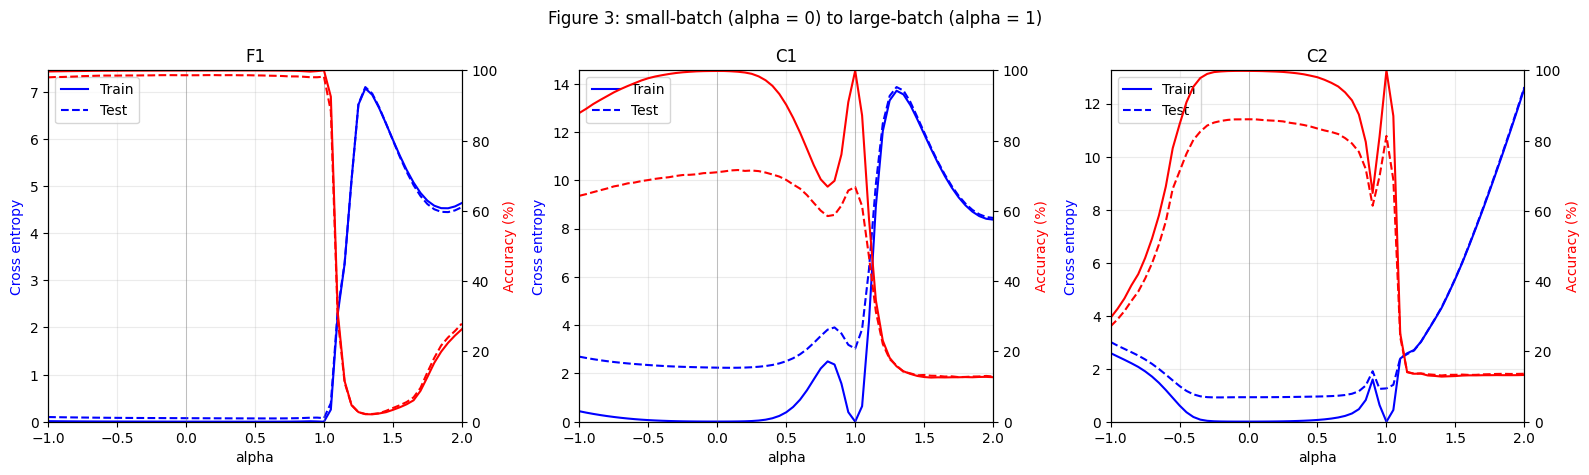

[
  {
    "network": "F1",
    "regime": "SB",
    "train_loss": 0.0018074389395381634,
    "test_loss": 0.0752120608329773,
    "train_accuracy": 0.9995666666666667,
    "test_accuracy": 0.9861
  },
  {
    "network": "F1",
    "regime": "LB",
    "train_loss": 2.484029789144794e-05,
    "test_loss": 0.07630268864631652,
    "train_accuracy": 1.0,
    "test_accuracy": 0.982
  },
  {
    "network": "C1",
    "regime": "SB",
    "train_loss": 0.00695249404668808,
    "test_loss": 2.2390629150390624,
    "train_accuracy": 0.9982,
    "test_accuracy": 0.71
  },
  {
    "network": "C1",
    "regime": "LB",
    "train_loss": 0.004335681063532829,
    "test_loss": 3.029056231689453,
    "train_accuracy": 0.99886,
    "test_accuracy": 0.6678
  },
  {
    "network": "C2",
    "regime": "SB",
    "train_loss": 0.004697497942447663,
    "test_loss": 0.9247995544433594,
    "train_accuracy": 0.9984,
    "test_accuracy": 0.8607
  },
  {
    "network": "C2",
    "regime": "LB",
    "train_loss": 5.

In [5]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4.8))
endpoint_rows = []
for axis, architecture in zip(axes, MODEL_FACTORIES):
    rows = classification_curves[architecture]
    alpha_values = [row["alpha"] for row in rows]
    accuracy_axis = axis.twinx()
    for split, style in (("train", "-"), ("test", "--")):
        axis.plot(alpha_values, [row[split]["loss"] for row in rows], color="blue", linestyle=style,
                  linewidth=1.5, label=split.capitalize())
        accuracy_axis.plot(alpha_values, [100 * row[split]["accuracy"] for row in rows],
                           color="red", linestyle=style, linewidth=1.5)
    axis.set(title=architecture, xlabel="alpha", ylabel="Cross entropy", xlim=(-1, 2), ylim=(0, None))
    accuracy_axis.set(ylabel="Accuracy (%)", ylim=(0, 100))
    axis.yaxis.label.set_color("blue")
    accuracy_axis.yaxis.label.set_color("red")
    axis.axvline(0, color="gray", linewidth=0.6, alpha=0.5)
    axis.axvline(1, color="gray", linewidth=0.6, alpha=0.5)
    axis.grid(alpha=0.25)
    axis.legend(loc="upper left")
    for alpha, regime in ((0, "SB"), (1, "LB")):
        row = next(row for row in rows if row["alpha"] == alpha)
        endpoint_rows.append({"network": architecture, "regime": regime,
                              "train_loss": row["train"]["loss"], "test_loss": row["test"]["loss"],
                              "train_accuracy": row["train"]["accuracy"], "test_accuracy": row["test"]["accuracy"]})
figure.suptitle("Figure 3: small-batch (alpha = 0) to large-batch (alpha = 1)")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "figure3_f1_c1_c2.png", dpi=180)
figure.savefig(RESULTS_DIR / "figure3_f1_c1_c2.pdf")
atomic_json(RESULTS_DIR / "endpoint_metrics.json", endpoint_rows)
plt.show()
print(json.dumps(endpoint_rows, indent=2))


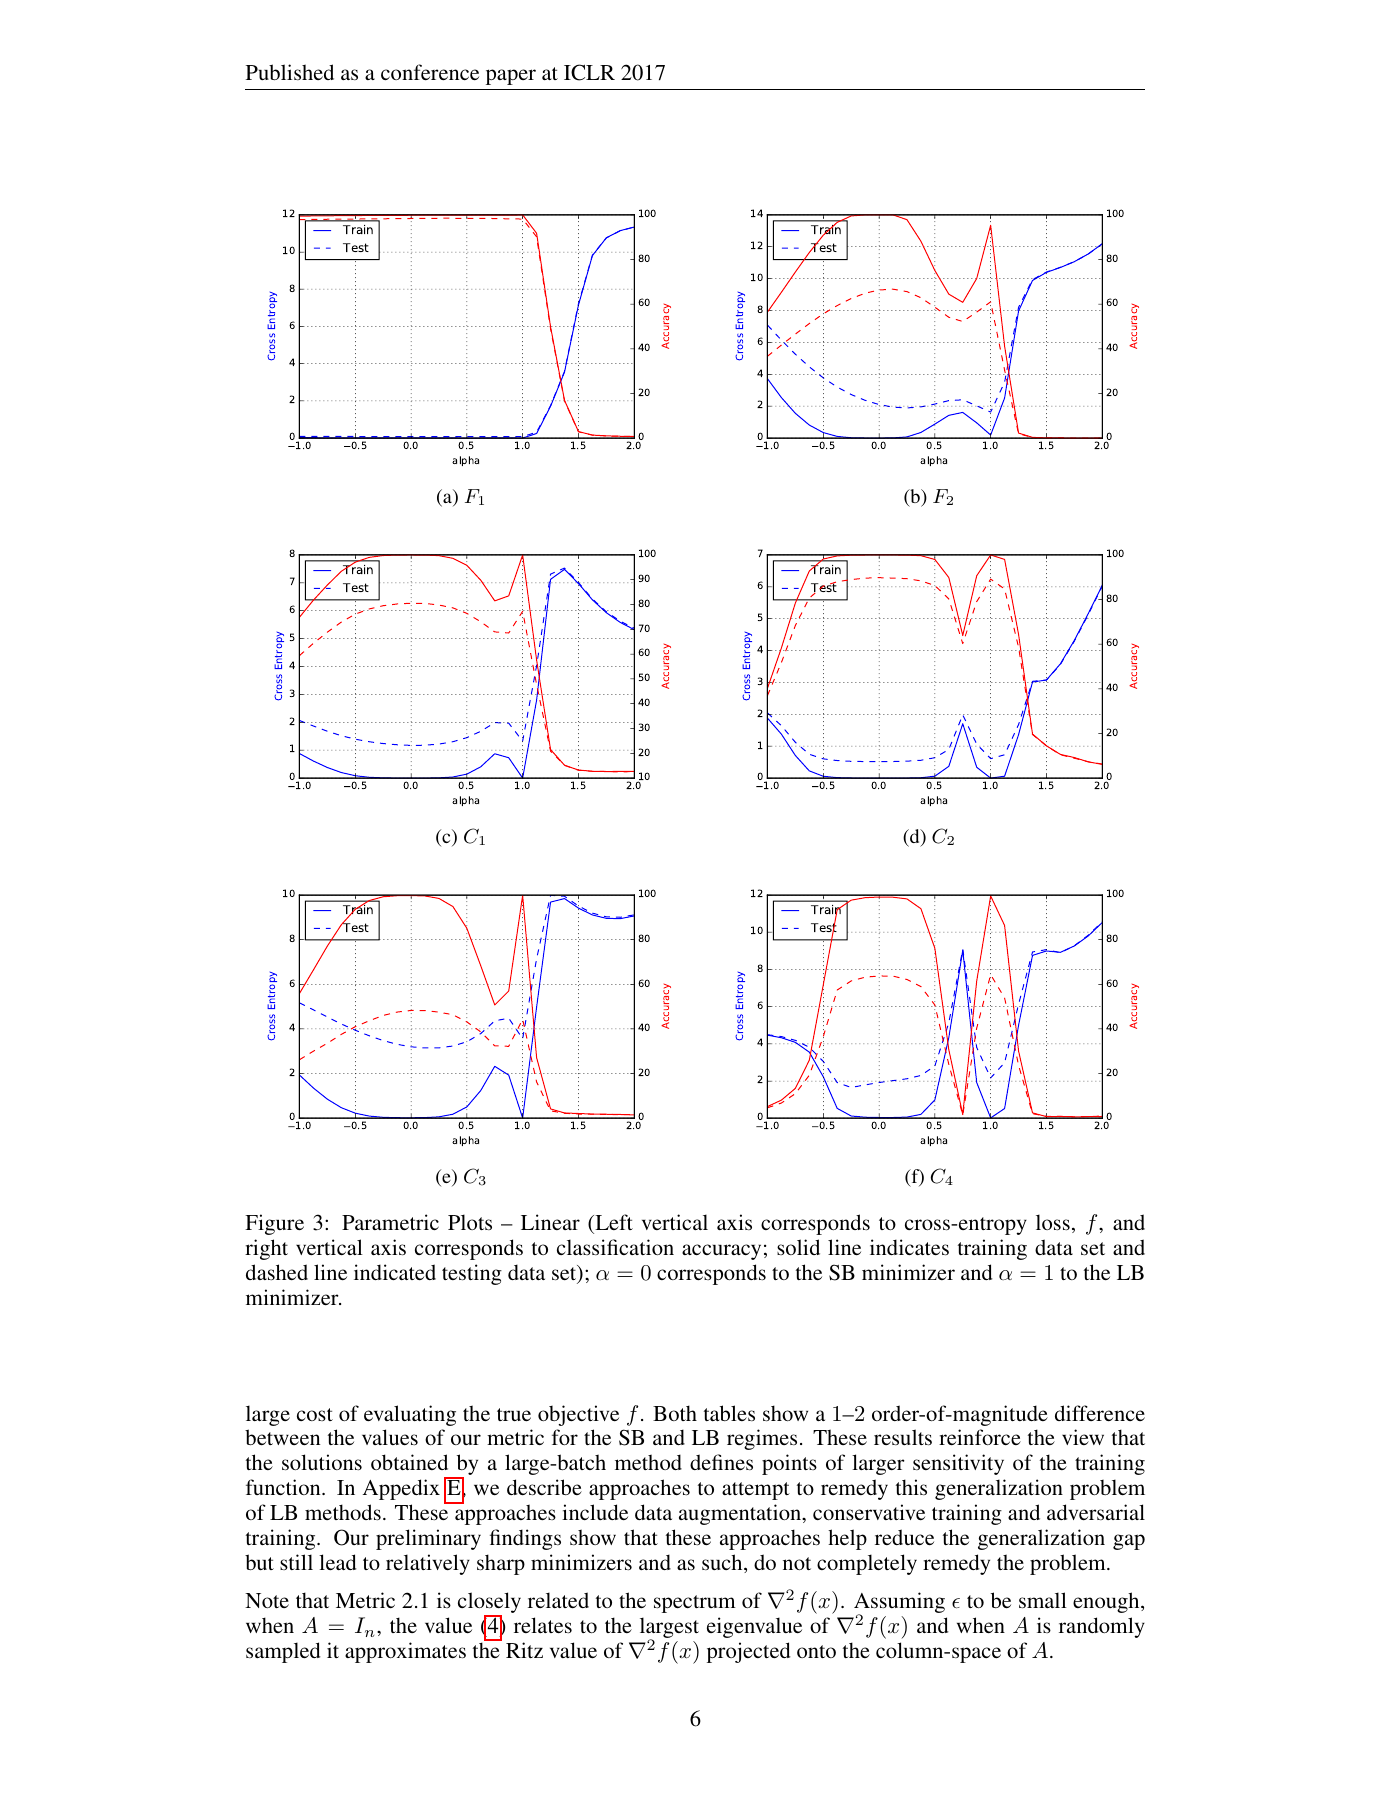

In [6]:
from IPython.display import Image

display(Image(filename=str(PROJECT_DIR / "results_large_batch/figure3_reference.png")))
